<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 01 · Lattices, orbitals and building any tight-binding model

**Goals**: define a lattice and orbitals, add on-site terms and hoppings, see 1st/2nd/3rd
neighbour shells, build spinful models with exchange and spin-orbit coupling, and use
Slater-Koster tables for s, p, d orbitals.

A tight-binding Hamiltonian is

$$H = \sum_{i} \varepsilon_i\, c_i^\dagger c_i + \sum_{i j \mathbf{R}} t_{ij}(\mathbf{R})\, c_{i,\mathbf 0}^\dagger c_{j,\mathbf R} + \text{h.c.}$$

and its Bloch form (atomic gauge) is
$H_{ij}(\mathbf k)=\sum_{\mathbf R} t_{ij}(\mathbf R)\, e^{i\mathbf k\cdot(\mathbf R+\mathbf r_j-\mathbf r_i)}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

## 1. Your first model: graphene in five lines
Positions are fractional by default. Bonds are found automatically by distance shell.

In [2]:
lat = hf.Lattice([[1, 0], [0.5, np.sqrt(3)/2]],
                 [("A", [1/3, 1/3]), ("B", [2/3, 2/3])])
g = hf.Model(lat, name="my graphene")
nbonds = g.add_neighbors(-1.0, shell=1)      # -t on all nearest-neighbour bonds
print(nbonds, "bonds per cell")
print(g.summary())

3 bonds per cell
hopforge Model 'my graphene'
  periodic dims : 2   (space dim 2)
  orbitals      : 2  ['A', 'B']
  spinful       : False  -> 2 bands
  hopping terms : 3 (+ h.c.)
  special points: ['G']


## 2. Seeing the neighbour shells
`plot_lattice` colours the 1st, 2nd and 3rd neighbour shells, and the legend gives each shell's distance $d$ and coordination number $z$.

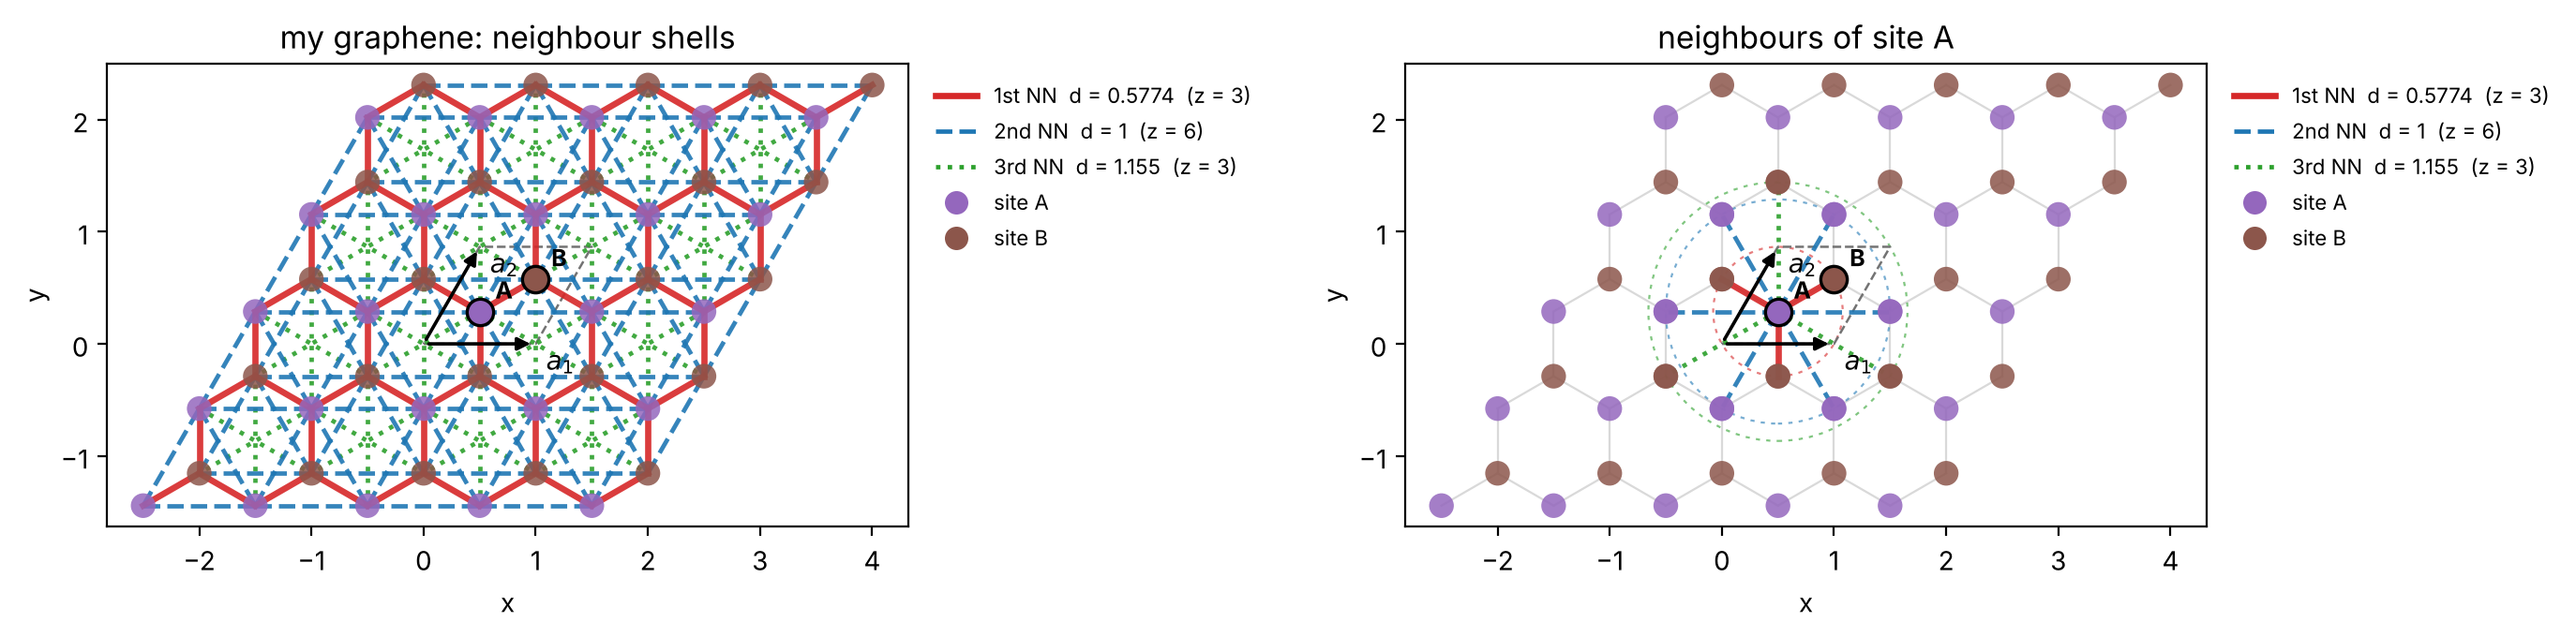

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hf.plot_lattice(g, ax=axes[0])
hf.plot_lattice(g, highlight="A", ax=axes[1], title="neighbours of site A")
plt.tight_layout()

In [4]:
for n, shell in enumerate(hf.plotting.neighbor_shells(g, 3), start=1):
    print(f"shell {n}: d = {shell['distance']:.4f}, coordination = {set(shell['coordination'].values())}")

shell 1: d = 0.5774, coordination = {3}
shell 2: d = 1.0000, coordination = {6}
shell 3: d = 1.1547, coordination = {3}


## 3. Adding hoppings by hand
`add_hopping(t, i, j, R)` adds $\langle i,0|H|j,R\rangle=t$ **and its Hermitian conjugate**, so add each bond only once.

In [5]:
chain = hf.Model(hf.Lattice([[1.0]], [("A", [0.0])]), name="chain")
chain.add_onsite(0.0, "A")
chain.add_hopping(-1.0, "A", "A", [1])        # A(0) -> A(1); A(1)->A(0) is automatic
k = np.linspace(-0.5, 0.5, 5)
print(chain.energies(k).ravel())
print(-2*np.cos(2*np.pi*k))

[ 2.0000000e+00 -1.2246468e-16 -2.0000000e+00 -1.2246468e-16
  2.0000000e+00]
[ 2.0000000e+00 -1.2246468e-16 -2.0000000e+00 -1.2246468e-16
  2.0000000e+00]


## 4. Second neighbours and site energies
Add an NNN hopping `t2` and a staggered potential: graphene → hBN-like.

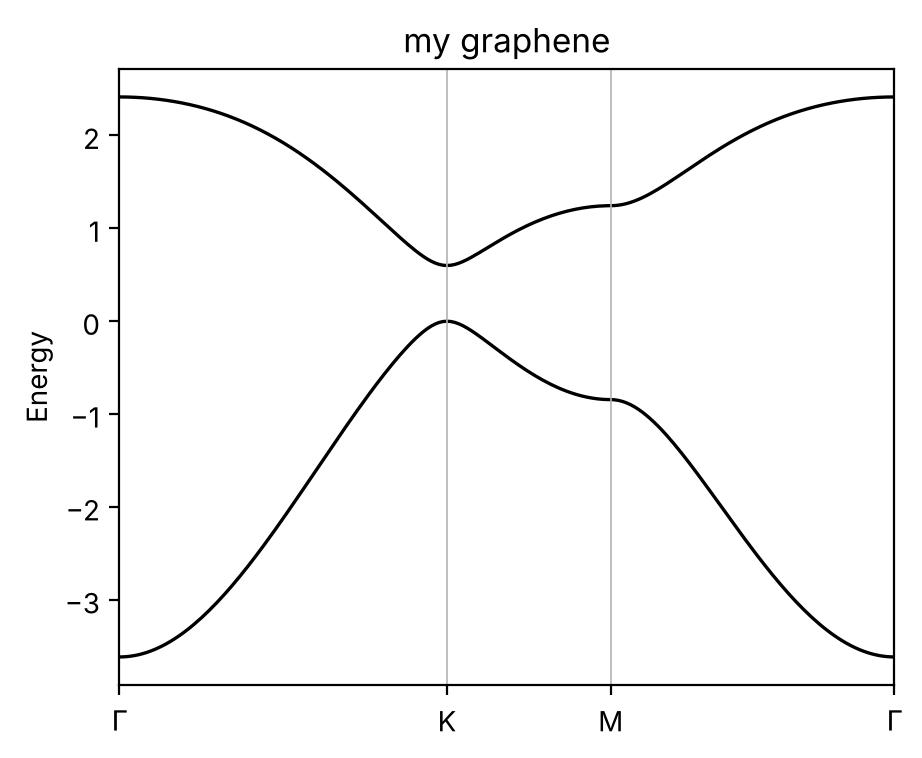

In [6]:
g2 = g.copy()
g2.add_neighbors(-0.1, shell=2)
g2.add_onsite(+0.3, "A").add_onsite(-0.3, "B")
g2.special_points = M.honeycomb().special_points
ax = g2.plot_bands(["G", "K", "M", "G"])

## 5. Spinful models: exchange, Rashba, intrinsic SOC
With `spinful=True` every amplitude can be a 2×2 spin matrix. Basis order: orbital-major (orb0↑, orb0↓, orb1↑, …).

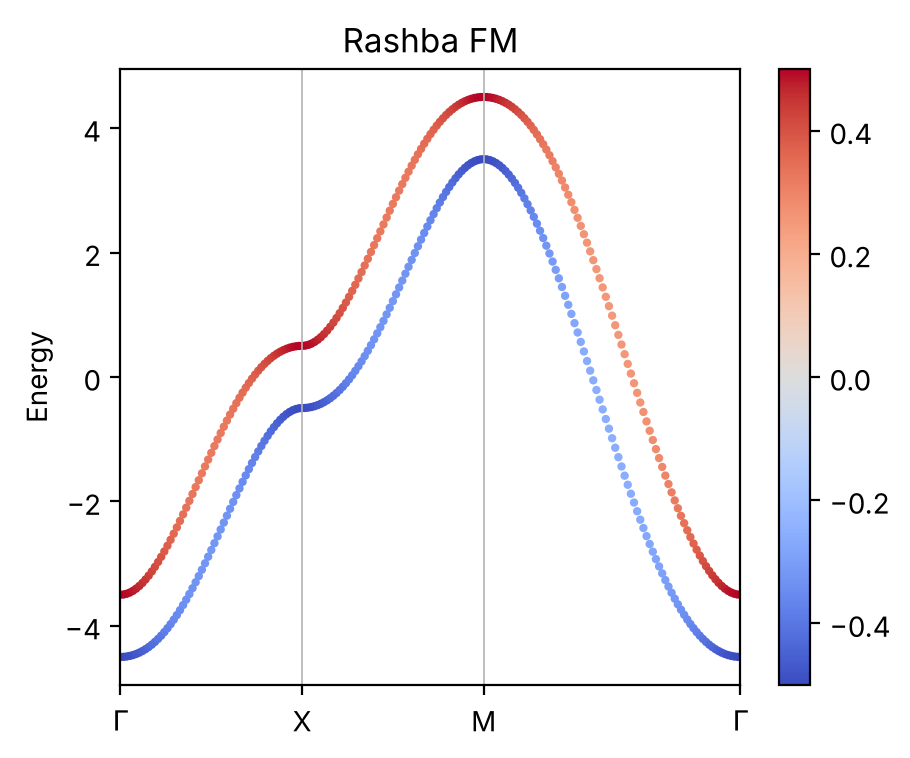

In [7]:
sq = hf.Model(hf.Lattice([[1, 0], [0, 1]], [("A", [0, 0])]), spinful=True, name="Rashba FM")
sq.add_neighbors(-1.0, 1)
sq.add_rashba(0.3)                       # i*alpha*(sigma x d).z on NN bonds
sq.add_exchange(0.5, (0, 0, 1))          # J m.sigma
sq.special_points = M.square().special_points
ax = sq.plot_bands(["G", "X", "M", "G"], weights=sq.spin_operator("z"))

Spin-dependent hoppings can be written with Pauli matrices, e.g. the Kane-Mele term $i\lambda\nu_{ij}\sigma_z$:

In [8]:
print(hf.pauli('z'))
print(hf.spin_block(0, 0, 0, 1j*0.06))   # t0*1 + tx*sx + ty*sy + tz*sz

[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
[[0.+0.06j 0.+0.j  ]
 [0.+0.j   0.-0.06j]]


## 6. Multi-orbital models and Slater-Koster
Orbital names `site:kind` tell hopforge the real orbital (`s, px, py, pz, dxy, dyz, dz2, dxz, dx2-y2`). `add_slater_koster` then builds all hoppings from $V_{ll'm}$ parameters.

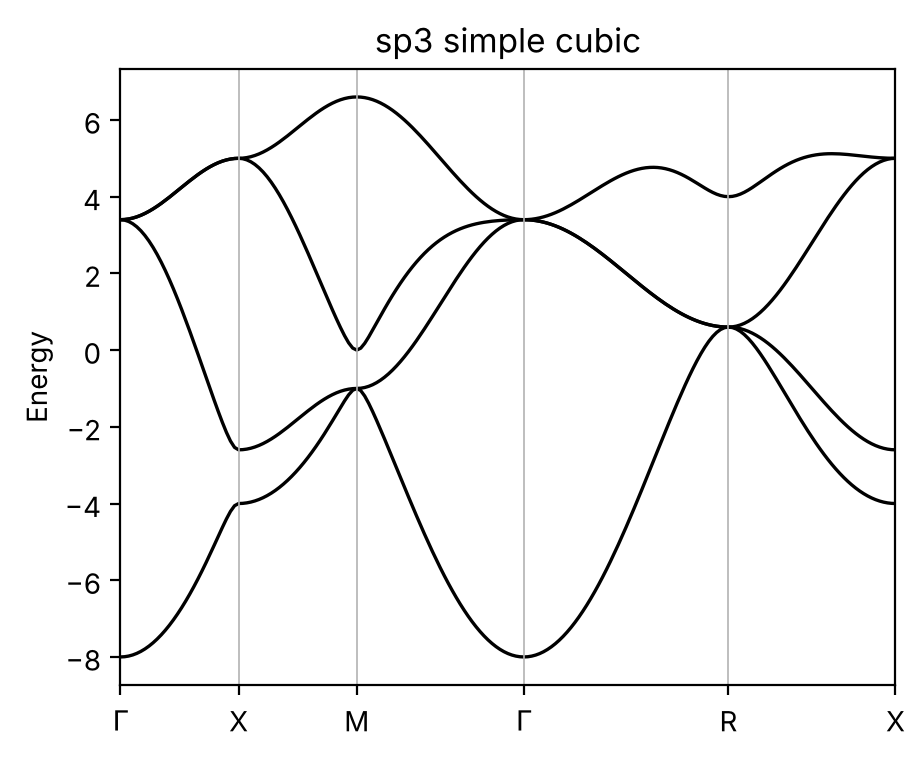

In [9]:
lat = hf.Lattice(np.eye(3), [("Si:s", [0,0,0]), ("Si:px", [0,0,0]), ("Si:py", [0,0,0]), ("Si:pz", [0,0,0])])
sp = hf.Model(lat, name="sp3 simple cubic")
sp.add_onsite(-2.0, "Si:s")
sp.add_onsite(+2.0, ["Si:px", "Si:py", "Si:pz"])
sp.add_slater_koster({"sss": -1.0, "sps": 1.2, "pps": 1.5, "ppp": -0.4}, shell=1)
sp.special_points = M.cubic().special_points
sp.plot_bands(["G", "X", "M", "G", "R", "X"]);

In [10]:
d = [1, 1, 0]
for a, b in [("s", "px"), ("px", "py"), ("dxy", "dxy"), ("pz", "dz2")]:
    print(f"E_{a},{b}(d={d}) =", round(hf.slater_koster(a, b, d, dict(sps=1, pps=1, ppp=-0.5, pds=1, pdp=0.3, dds=-1, ddp=0.5, ddd=-0.1)), 4))

E_s,px(d=[1, 1, 0]) = 0.7071
E_px,py(d=[1, 1, 0]) = 0.75
E_dxy,dxy(d=[1, 1, 0]) = -0.775
E_pz,dz2(d=[1, 1, 0]) = 0.0


## 7. Matrix-valued (k·p-style) lattice models
`add_onsite_matrix` and `add_hopping_matrix` take whole blocks: ideal for models written as $d(\mathbf k)\cdot\sigma$. Here is the QWZ model built by hand:

In [11]:
sx, sy, sz = hf.pauli('x'), hf.pauli('y'), hf.pauli('z')
q = hf.Model(hf.Lattice(np.eye(2), [("a", [0, 0]), ("b", [0, 0])]), name="QWZ by hand")
m_ = 1.0
q.add_onsite_matrix(m_ * sz, ["a", "b"])
q.add_hopping_matrix(sz/2 - 0.5j*sx, ["a", "b"], ["a", "b"], [1, 0])   # gives cos kx sz + sin kx sx
q.add_hopping_matrix(sz/2 - 0.5j*sy, ["a", "b"], ["a", "b"], [0, 1])
k = np.random.rand(3, 2)
print(np.allclose(q.hamiltonian(k), M.qwz(1.0).hamiltonian(k)))

True


## 8. Export
Any model can be written as a Wannier90 `_hr.dat` file (and so passed to WannierTools or other codes).

In [12]:
M.kane_mele().to_wannier90_hr("kane_mele_hr.dat")
print(open("kane_mele_hr.dat").read()[:300])

written by hopforge (Kane-Mele)
4
7
    1    1    1    1    1    1    1
   -1    0    0    1    1    0.000000    0.060000
   -1    0    0    2    1    0.000000    0.000000
   -1    0    0    3    1    0.000000    0.000000
   -1    0    0    4    1    0.000000    0.000000
   -1    0    0    1    2   


## Exercises
1. Build the Lieb lattice yourself and check the flat band at $E=0$ against `M.lieb()`.
2. Add a 3rd-neighbour hopping to graphene and see how the particle-hole symmetry breaks.
3. Put px, py on a honeycomb lattice with Slater-Koster parameters and plot the four bands.

---
## Quiz 01: Lattices and models

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [13]:
quiz = hf.Quiz(1)
quiz.interactive()

In [14]:
quiz.show()

=== Quiz 01: Lattices, orbitals and building a tight-binding model ===

Q1. In hopforge, `m.add_hopping(t, 'A', 'B', [1, 0])` adds which matrix element(s)?
   (a) t on the A-B bond and also on the B-A bond with the same R
   (b) <A,0|H|B,(1,0)> = t and its Hermitian conjugate <B,0|H|A,(-1,0)> = t*
   (c) Only <A,0|H|B,R=(1,0)> = t
   (d) t on every A-B bond of the lattice

Q2. Graphene's two-atom unit cell and one p_z orbital per atom give how many bands (spinless)?
   (a) 3
   (b) 4
   (c) 2
   (d) 1

Q3. A spinful model with 3 orbitals per cell has how many bands?
   (a) 5
   (b) 9
   (c) 6
   (d) 3

Q4. In hopforge's spinful basis ordering, basis index 5 corresponds to
   (a) orbital 5, spin up
   (b) orbital 1, spin down
   (c) orbital 2, spin up
   (d) orbital 2, spin down

Q5. For the honeycomb lattice (a = 1), the 1st, 2nd and 3rd neighbour coordination numbers are
   (a) 3, 6, 3
   (b) 6, 6, 12
   (c) 3, 6, 6
   (d) 3, 3, 6

Q6. The nearest-neighbour distance in graphene with l

In [15]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0